# Mini Project — Document Boundary Detection Tool

This project implements: load → grayscale → Gaussian blur → Canny → morphology and noise filtering → contour selection → original-image overlay → saved output.

**Before running:** extract the project ZIP and install `requirements.txt`. Open this notebook inside the extracted project. In Colab, upload/extract the complete project ZIP first. The notebook uses the accompanying `document_detector.py` and the included dataset. Embedded figures below were produced by executing the cells.

The dataset has 15 files: 8 public camera photos, 3 archival scans/digital reproductions with added margins, 2 added-shadow variants and 2 blur variants. There are 11 source images plus four variants. See `dataset/SOURCES.md` and `manifest.json`.

In [1]:
from pathlib import Path
import sys, json, csv
import cv2 as cv
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROJECT = Path.cwd()
if not (PROJECT / "document_detector.py").exists():
    PROJECT = PROJECT / "Document_Boundary_Detection"
if not (PROJECT / "document_detector.py").exists():
    raise FileNotFoundError("Extract the full project and open the notebook inside its folder.")
sys.path.insert(0, str(PROJECT))
from document_detector import load_image, detect_document, process_image
print("OpenCV", cv.__version__, "| NumPy", np.__version__)
print("Input images:", len(list((PROJECT / "dataset" / "images").iterdir())))

from io import BytesIO

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))


OpenCV 4.14.0 | NumPy 2.3.5
Input images: 15


## Understanding the implementation

| Step | What it does |
|---|---|
| Working-size copy | Makes processing faster while retaining the original for final output |
| Grayscale | Converts BGR into one intensity channel |
| Gaussian blur | Suppresses small fluctuations before derivatives |
| Canny | Produces binary edges using two gradient thresholds |
| Morphological closing | Reconnects short gaps in the outline |
| Component filtering | Removes isolated edge clusters below 25 pixels |
| Contours | Orders candidate boundaries by enclosed area |
| Overlay | Maps the boundary back to original coordinates and draws green lines |

Opening is not used on the thin Canny map because erosion can remove the desired outline. Closing is a morphological operation; component filtering performs the separate isolated-noise cleanup.

The default compares Canny 40/120 with 30/90. For each attempt it seeks the largest plausible convex quadrilateral, then keeps the larger proposal. This can recover a faint outer edge when an internal rectangle is stronger. It is still a heuristic. `selection="largest"` uses only the primary thresholds and draws the actual largest sufficiently large contour.

The full implementation is in `document_detector.py`; the next cell displays every stage for an image.

Status: boundary_candidate | Largest plausible four-corner contour
Chosen Canny thresholds: [40, 120] | Area ratio: 0.6801


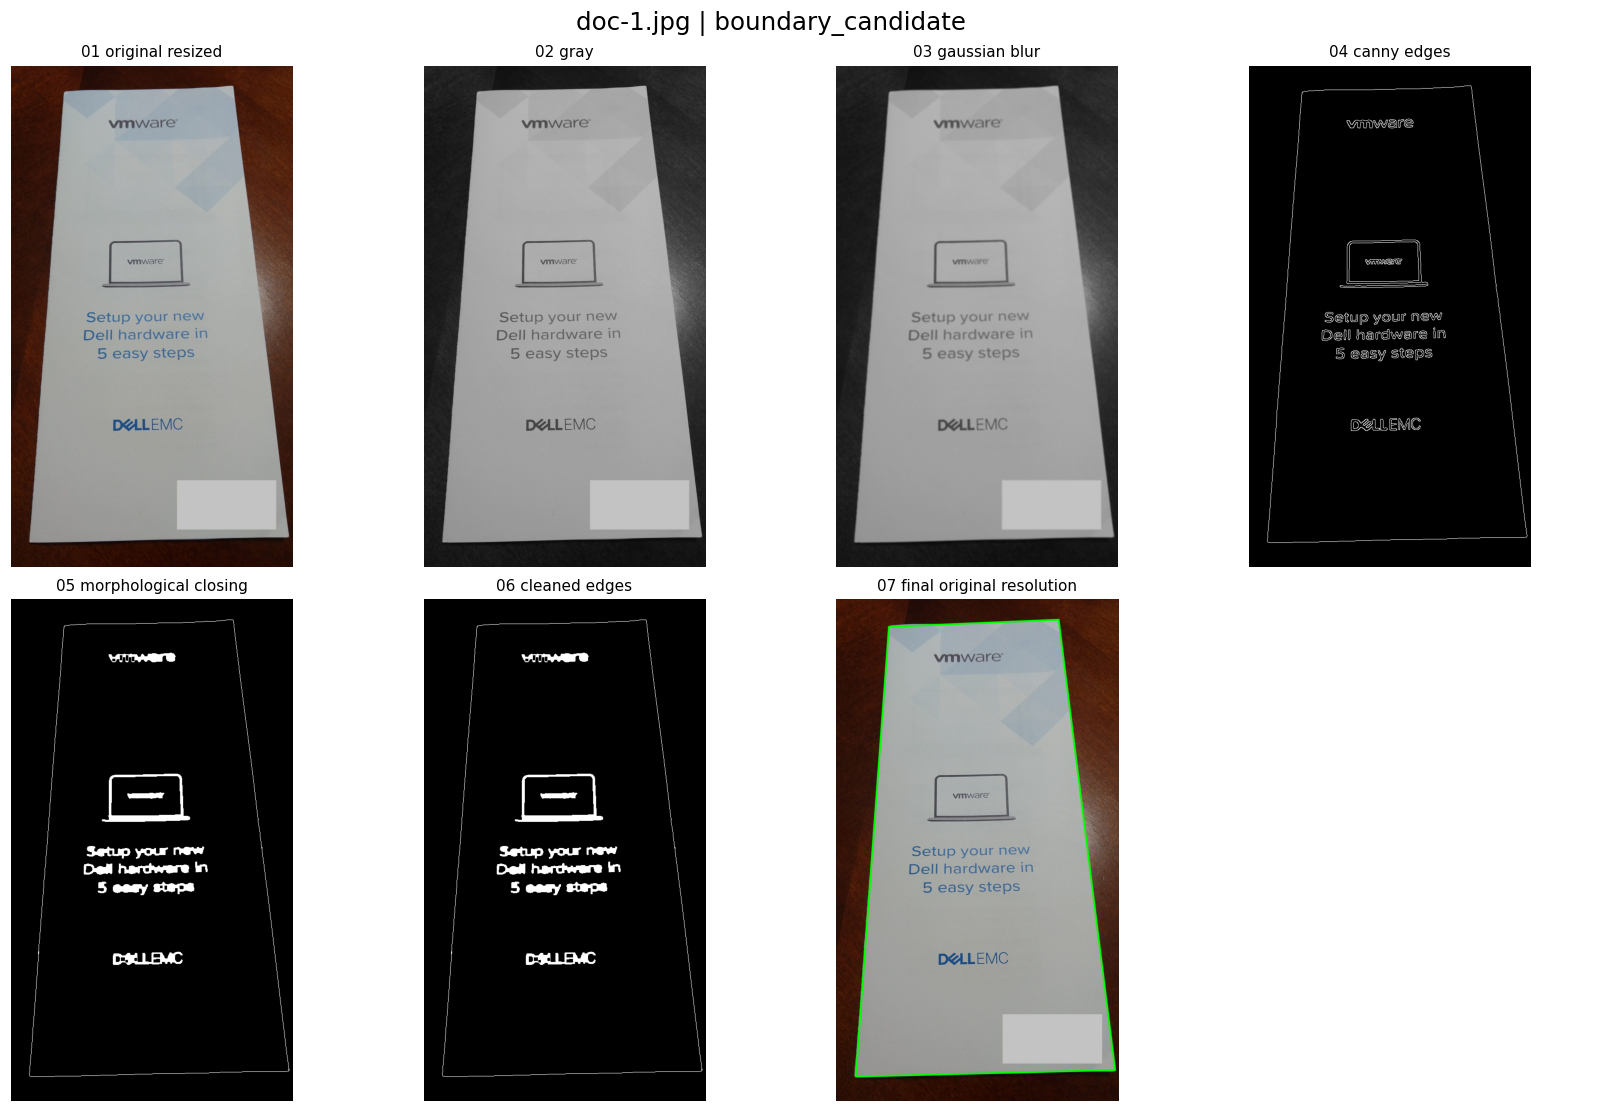

In [2]:
def inspect_document(filename, **options):
    image = load_image(PROJECT / "dataset" / "images" / filename)
    overlay, info, stages = detect_document(image, **options)
    panels = list(stages.items()) + [("07_final_original_resolution", overlay)]
    fig, axes = plt.subplots(2, 4, figsize=(15, 10), constrained_layout=True)
    for ax, (label, panel) in zip(axes.flat, panels):
        if panel.ndim == 3:
            ax.imshow(cv.cvtColor(panel, cv.COLOR_BGR2RGB))
        else:
            ax.imshow(panel, cmap="gray", vmin=0, vmax=255)
        ax.set_title(label.replace("_", " "), fontsize=10)
        ax.axis("off")
    for ax in list(axes.flat)[len(panels):]:
        ax.axis("off")
    fig.suptitle(filename + " | " + info["status"], fontsize=16)
    show_figure(fig)
    plt.close(fig)
    print("Status:", info["status"], "|", info["reason"])
    print("Chosen Canny thresholds:", info["canny_thresholds"], "| Area ratio:", info["area_ratio"])
    return info

brochure = inspect_document("doc-1.jpg")


## Perspective and uneven lighting

Inspect the green overlay on the document spread. Corners are polygon estimates: curled boundaries need not be perfectly straight. The lower-threshold attempt can help retain a weak exterior edge. The code does not read text or verify document identity.

Status: boundary_candidate | Largest plausible four-corner contour
Chosen Canny thresholds: [30.0, 90.0] | Area ratio: 0.6215


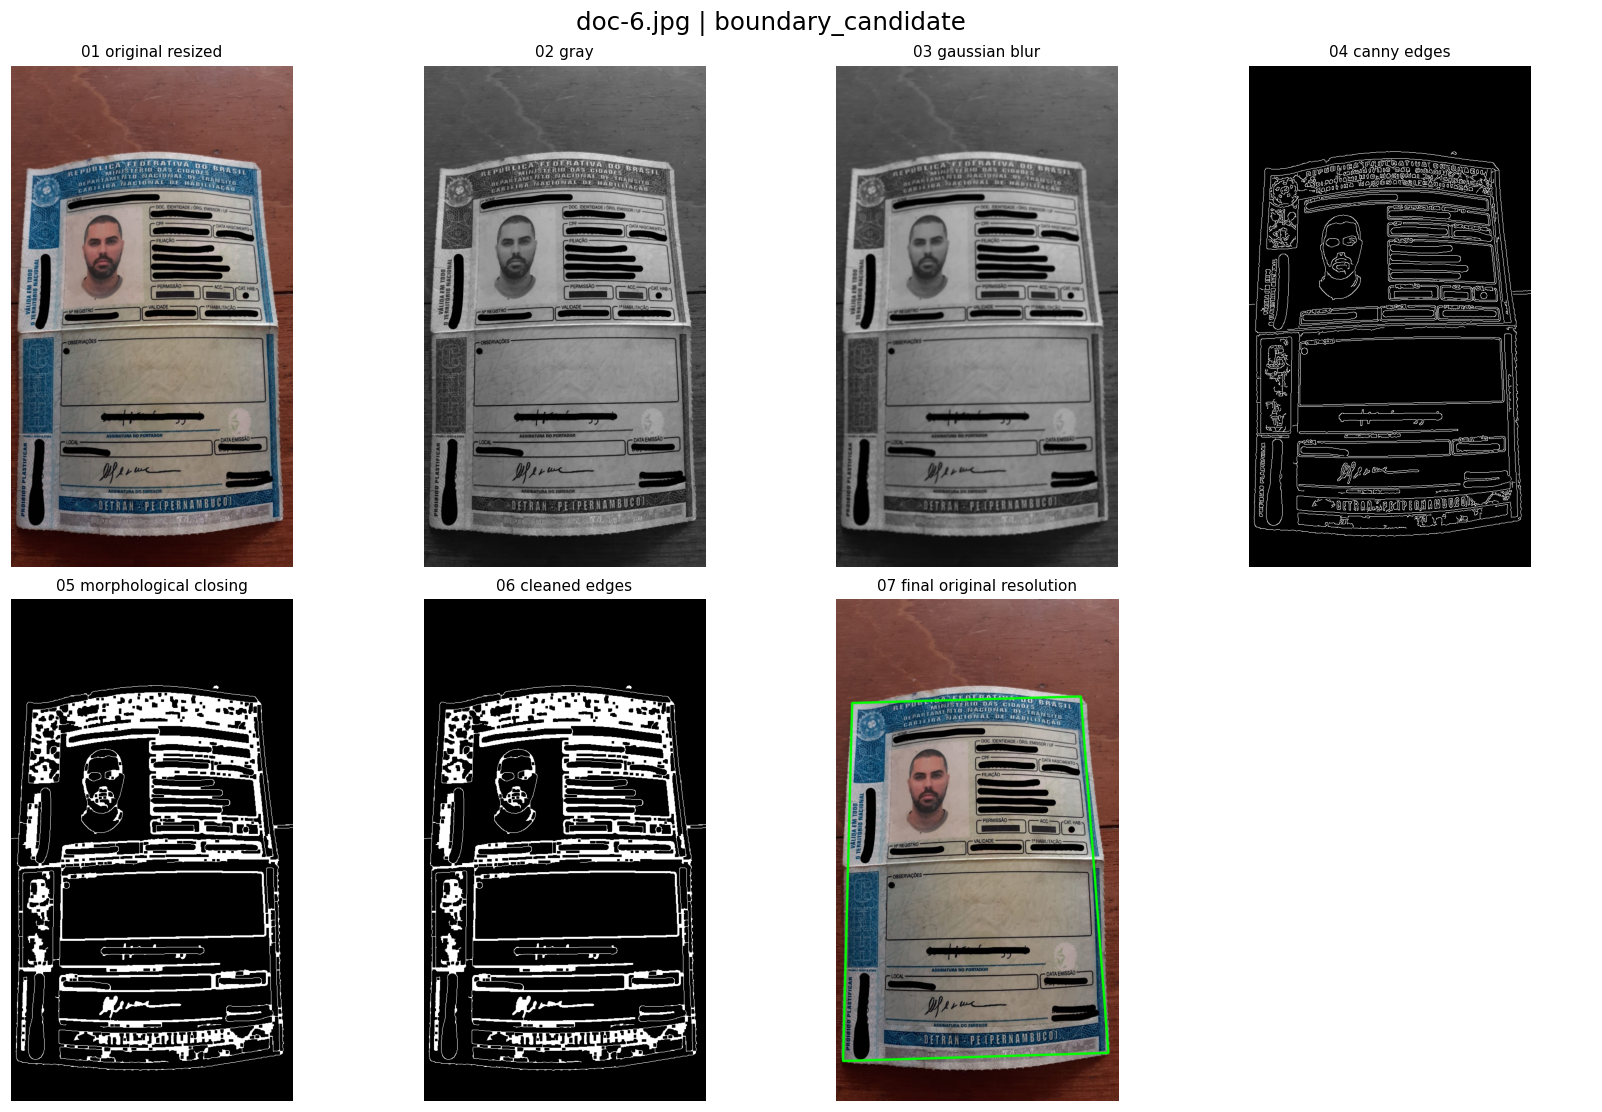

In [3]:
spread = inspect_document("doc-6.jpg")


## A retained failure case

The light background and shadows in this image are difficult for the baseline. A failure is a valid outcome to document. The app reports `no_boundary` when it cannot find a sufficiently large closed quadrilateral, and saves the original image without inventing corners.

Status: no_boundary | No sufficiently large, closed four-corner boundary
Chosen Canny thresholds: [40, 120] | Area ratio: None


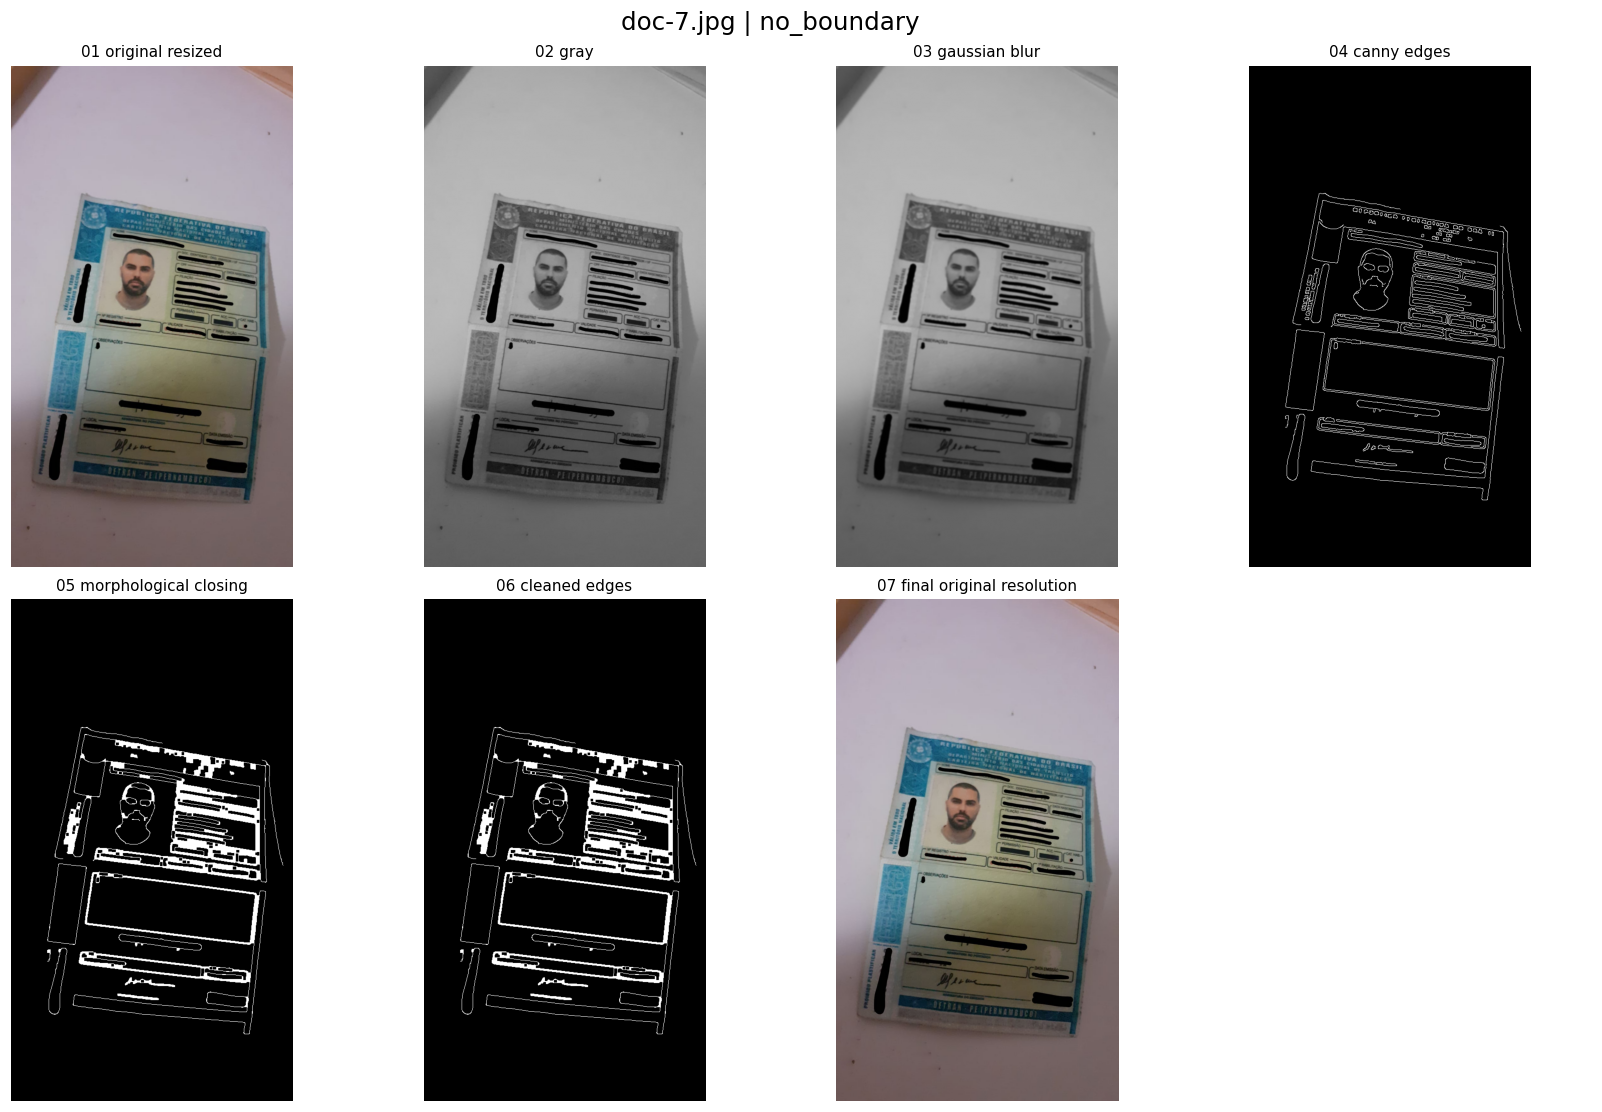

In [4]:
difficult = inspect_document("doc-7.jpg")


## Save a final output for one image

This writes the full-resolution overlay, all intermediate PNGs and `status.json`. Change the filename below to try another bundled image. For your own image, pass its full path to `process_image` instead.

In [5]:
saved = process_image(
    PROJECT / "dataset" / "images" / "doc-1.jpg",
    PROJECT / "notebook_example"
)
print("Saved:", PROJECT / "notebook_example" / "document_boundary.png")
print("Final dimensions:", saved["original_size"])


Saved: /workspace/scratch/9349416e6847/Document_Boundary_Detection/notebook_example/document_boundary.png
Final dimensions: [1152, 2048]


## Compare strict largest-contour mode

The baseline directly draws the largest sufficiently large contour. A large contour can still describe a partial document, a shadow or a background shape. The default adds geometric checks and a second threshold attempt, but it can still fail. Inspect both outputs visually.

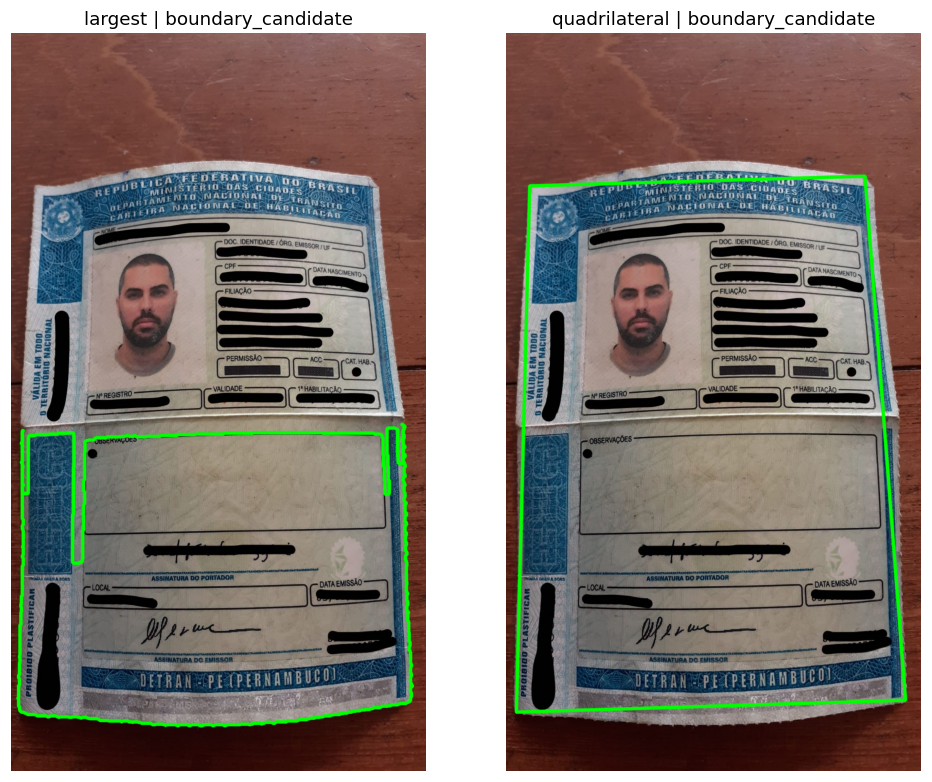

In [6]:
image = load_image(PROJECT / "dataset" / "images" / "doc-6.jpg")
fig, axes = plt.subplots(1, 2, figsize=(9, 7), constrained_layout=True)
for ax, mode in zip(axes, ["largest", "quadrilateral"]):
    overlay, info, _ = detect_document(image, selection=mode)
    ax.imshow(cv.cvtColor(overlay, cv.COLOR_BGR2RGB))
    ax.set_title(mode + " | " + info["status"])
    ax.axis("off")
show_figure(fig)
plt.close(fig)


## Review the complete 15-image run

The project includes saved outputs for all 15 inputs. The contact sheet below shows proposals and misses. A proposed polygon is not a ground-truth-verified correct detection. Source scenes and their variants are related, and settings were examined using this same practice set.

blur_03.png             boundary_candidate
blur_08.png             boundary_candidate
doc-1.jpg               boundary_candidate
doc-2.png               boundary_candidate
doc-3.jpg               boundary_candidate
doc-4.jpg               boundary_candidate
doc-5.jpg               no_boundary
doc-6.jpg               boundary_candidate
doc-7.jpg               no_boundary
doc-8.jpg               no_boundary
scan_01.png             boundary_candidate
scan_02.png             boundary_candidate
scan_03.png             boundary_candidate
shadow_01.png           boundary_candidate
shadow_02.png           boundary_candidate
Candidates: 12 / 15


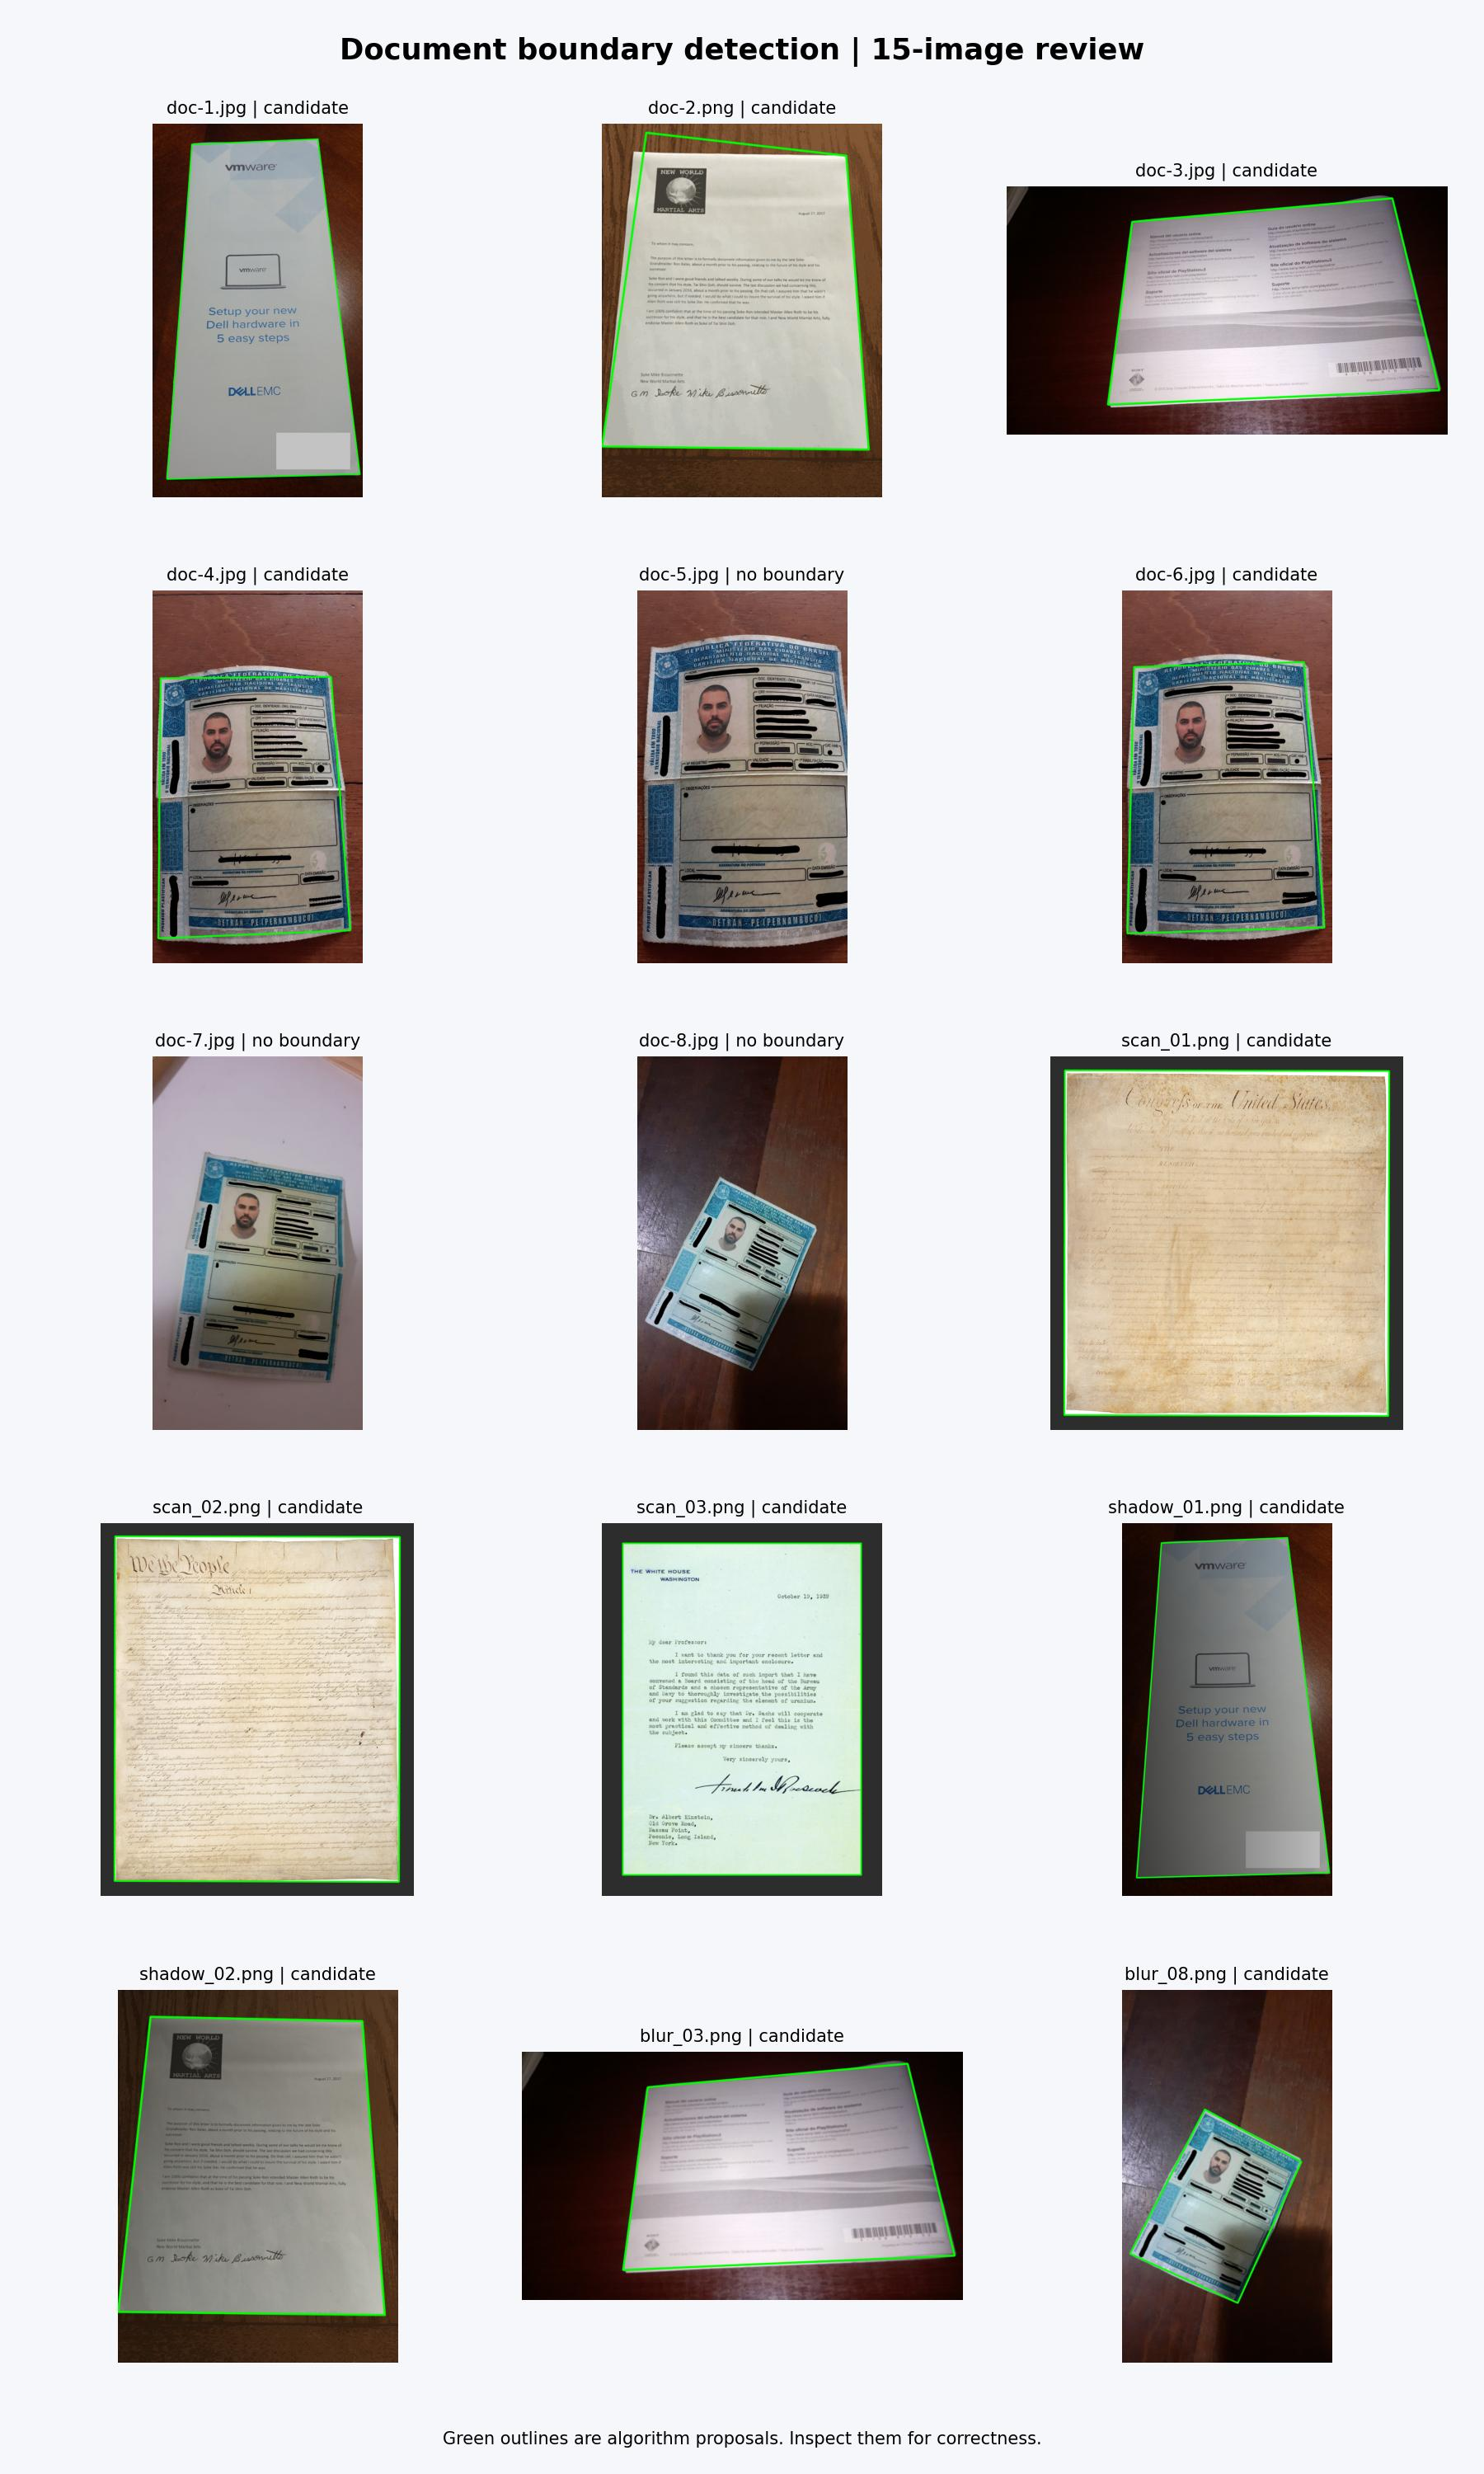

In [7]:
with (PROJECT / "results" / "summary.csv").open(newline="", encoding="utf-8") as stream:
    rows = list(csv.DictReader(stream))
for row in rows:
    print(f"{row['file']:<23} {row['status']}")
print("Candidates:", sum(row["status"] == "boundary_candidate" for row in rows), "/", len(rows))
display(Image(filename=str(PROJECT / "reports" / "all_results.jpg")))


## Conclusions and next experiments

The application implements every requested processing stage and saves intermediate evidence alongside each final overlay. It demonstrates the limits of using large closed contours for document detection.

Try `--low 20 --high 60`, `--kernel 7`, or `--single-pass`, and inspect both successes and failures. Change one setting at a time and preserve outputs in a new folder. Large morphology kernels can merge unrelated edges.

The three bordered archival scans have a known source-canvas rectangle; `reports/RESULTS.md` reports mask IoU for that limited geometry check. Original camera photos do not have manual ground-truth polygons, so no general accuracy percentage is reported. Heavily shadowed, cropped, curled, occluded or low-contrast pages can fail.

**Dataset note:** source photos are attributed to Daniel Gatis's docscan examples under the retained MIT license. The archival scans/reproductions come from Wikimedia Commons: the Bill of Rights, the Constitution (page 1) and Roosevelt’s reply to Einstein. Their public-domain source metadata is retained in dataset/licenses/. Added margins make their outer canvas observable.

**References:** [Contours](https://docs.opencv.org/4.x/d4/d73/tutorial_py_contours_begin.html), [Contour features](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html), [Canny](https://docs.opencv.org/4.x/da/d22/tutorial_py_canny.html), [Morphology](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html), [Source images](https://github.com/danielgatis/docscan).